In [2]:
# ==========================================
# CELL 1: Load & Inspect Benchmark Leaderboard
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the 5-fold cross-validation benchmark results
benchmark_df = pd.read_csv("../data/baseline_benchmark_results.csv")

print("--- Full 18-Experiment Benchmark Leaderboard (Sorted by F1-Score) ---")
leaderboard = benchmark_df.sort_values(
    by="F1_Score", ascending=False).reset_index(drop=True)
display(leaderboard.style.background_gradient(cmap="YlGnBu", subset=["Recall", "F1_Score", "ROC_AUC", "PR_AUC"]).format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1_Score": "{:.4f}", "ROC_AUC": "{:.4f}", "PR_AUC": "{:.4f}"
}))

--- Full 18-Experiment Benchmark Leaderboard (Sorted by F1-Score) ---


,Model,Strategy,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Random Forest,SMOTE,0.8096,0.5389,0.4595,0.4957,0.7915,0.5267
1,XGBoost,Class-Weighted,0.7882,0.4818,0.5067,0.4938,0.7676,0.5123
2,Random Forest,Class-Weighted,0.8148,0.5585,0.4398,0.4915,0.7905,0.5320
3,XGBoost,SMOTE,0.8169,0.5765,0.3851,0.4612,0.7695,0.5154
4,Logistic Regression,Class-Weighted,0.6848,0.3530,0.6552,0.4588,0.7344,0.4527
5,Logistic Regression,SMOTE,0.6826,0.3516,0.6595,0.4587,0.7341,0.4517
6,Gaussian Naive Bayes,Class-Weighted,0.6715,0.3368,0.6307,0.4391,0.7119,0.4256
7,Gaussian Naive Bayes,SMOTE,0.6504,0.3223,0.6476,0.4304,0.7063,0.4287
8,XGBoost,Unadjusted,0.8163,0.5871,0.3413,0.4300,0.7719,0.5151
9,Gaussian Naive Bayes,Unadjusted,0.7626,0.4188,0.4243,0.4214,0.7119,0.4256


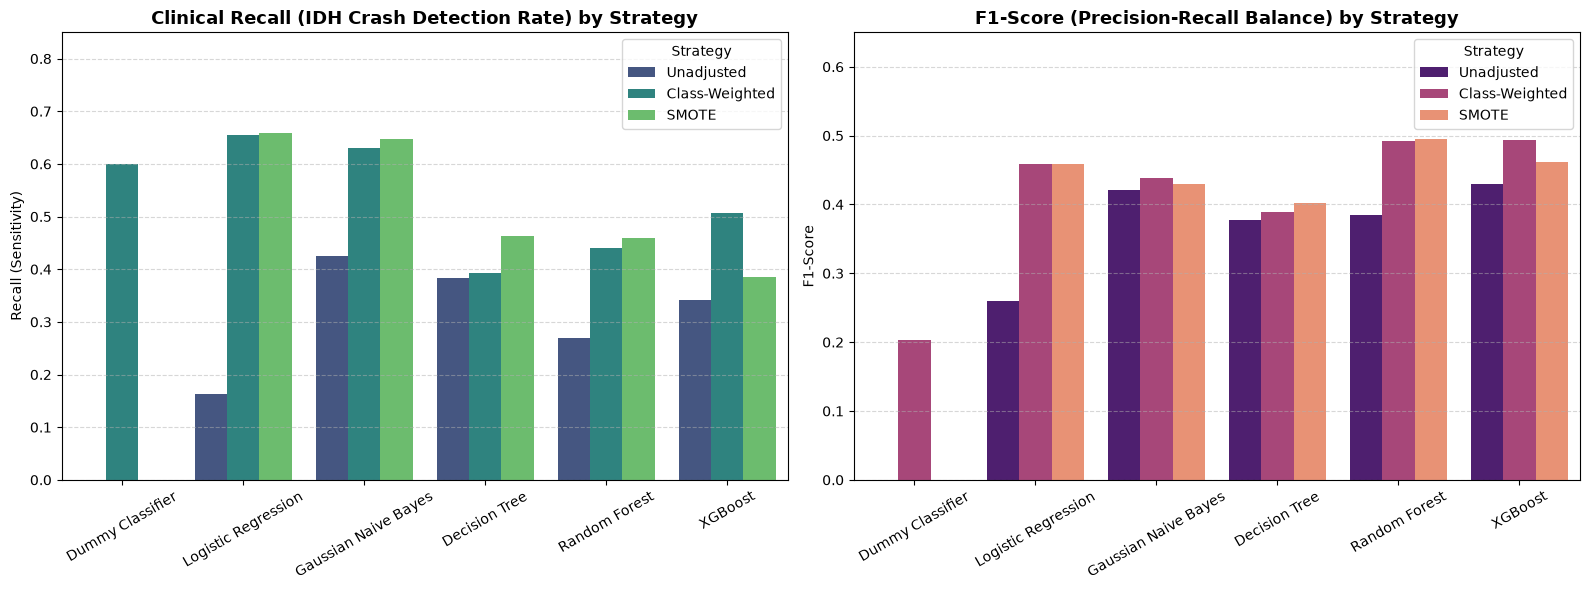

In [3]:
# ==========================================
# CELL 2: Strategy Impact on Recall & F1-Score
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Clinical Recall (Sensitivity) by Strategy
sns.barplot(
    data=benchmark_df, x="Model", y="Recall", hue="Strategy",
    palette="viridis", ax=axes[0]
)
axes[0].set_title("Clinical Recall (IDH Crash Detection Rate) by Strategy",
                  fontsize=13, fontweight="bold")
axes[0].set_ylabel("Recall (Sensitivity)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylim(0, 0.85)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Plot 2: F1-Score Balance by Strategy
sns.barplot(
    data=benchmark_df, x="Model", y="F1_Score", hue="Strategy",
    palette="magma", ax=axes[1]
)
axes[1].set_title("F1-Score (Precision-Recall Balance) by Strategy",
                  fontsize=13, fontweight="bold")
axes[1].set_ylabel("F1-Score")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_ylim(0, 0.65)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()